# LoRA

Câu lạc bộ muốn điều chỉnh một model văn bản pretrained để phân loại tài liệu thuật toán, nhưng GPU được cấp không đủ cho full fine-tuning: ngoài trọng số còn phải giữ gradient, trạng thái optimizer và activation cho mọi tham số. Có thể giữ nguyên trọng số nguồn và chỉ học một phần sửa nhỏ không? LoRA làm đúng việc đó bằng hai ma trận nhỏ đặt cạnh một phép tuyến tính. Buổi này tự cài một lớp LoRA, đếm tham số, kiểm gradient bằng NumPy, so với việc học toàn bộ ma trận, rồi chèn adapter vào kiến trúc DistilBERT để thấy phần được học thật sự gồm những gì.

> **Mục tiêu sau bài này**
>
> - Viết LoRA cho một lớp tuyến tính và tính đúng shape, hệ số scale, số tham số.
> - Giải thích vì sao một ma trận được khởi tạo 0 còn ma trận kia ngẫu nhiên.
> - Kiểm gradient của LoRA và phép merge bằng một đường tính độc lập.
> - Chèn LoRA vào một model Transformer theo tên module, đếm đúng phần được học và lập thí nghiệm so với full fine-tuning.

## Học phần thay đổi thay vì viết lại cả ma trận

Một lớp tuyến tính không bias nhận $d_{in}$ số và trả $d_{out}$ số bằng $\mathbf{y}=W_0\mathbf{x}$. $W_0$ có shape $(d_{out},d_{in})$. Trong full fine-tuning, ta học mọi phần tử của $W_0$. LoRA giữ $W_0$ cố định và viết thay đổi dưới dạng tích:

$$\mathbf{y}=W_0\mathbf{x}+\frac{\alpha}{r}BA\mathbf{x}.$$

$A$ có shape $(r,d_{in})$, đưa input xuống $r$ tọa độ; $B$ có shape $(d_{out},r)$, đưa chúng lên output. $r$ gọi là rank cấu hình và thường nhỏ; $\alpha$ điều khiển scale. Trong công thức này, scale là $\alpha/r$. Có biến thể dùng scale khác (PEFT có tùy chọn chia cho $\sqrt r$), nên khi dùng thư viện phải đọc đúng cấu hình thay vì chỉ nhìn tên LoRA.



Trường hợp $r=1$ cho thấy rõ nghĩa của hạng. Khi đó $A$ là một hàng $\mathbf{a}^\top$, $B$ là một cột $\mathbf{b}$, và phần sửa bằng $\frac{\alpha}{r}\mathbf{b}\,(\mathbf{a}^\top\mathbf{x})$: adapter chiếu input lên đúng một hướng $\mathbf{a}$ để được một con số, rồi đẩy output dọc theo đúng một hướng $\mathbf{b}$ với độ lớn tỉ lệ con số ấy. Với rank $r$, phần sửa là tổng của $r$ cặp như vậy, nên mọi vector $BA\mathbf{x}$ nằm trong không gian sinh bởi $r$ cột của $B$: $BA$ có hạng tối đa $r$. Giả thuyết của LoRA là phần sửa cần cho nhiệm vụ mới tập trung vào ít hướng. Nếu nhiệm vụ cần nhiều hướng sửa độc lập hơn $r$, adapter thiếu khả năng biểu diễn; rank là chỗ đặt cược vào giả thuyết đó, còn validation là chỗ kiểm.



**Hỏi nhanh.** Với $d_{in} = 8$, $d_{out} = 6$, $r = 2$, hai ma trận $A$ và $B$ có shape gì?

- A. $A$ là $(8, 2)$, $B$ là $(2, 6)$
- B. $A$ là $(2, 8)$, $B$ là $(6, 2)$
- C. $A$ là $(2, 6)$, $B$ là $(8, 2)$
- D. Cả hai đều là $(6, 8)$, cùng shape với $W_0$

<details><summary>Đáp án</summary>

B. $A$ là $(2, 8)$, $B$ là $(6, 2)$

$A$ nhận input 8 chiều nên có 8 cột. $B$ trả output 6 chiều nên có 6 hàng. $BA$ có shape $(6, 8)$, đúng bằng $W_0$. $(8, 2)$ và $(2, 6)$ là shape của $A^\top$ và $B^\top$, nhầm quy ước $\mathbf{y} = W\mathbf{x}$ với cách viết `X @ W.T` cho batch xếp theo hàng. $(2, 6)$ và $(8, 2)$ là đảo $d_{in}$ với $d_{out}$. Hai ma trận $(6, 8)$ thì không nhân được với nhau, và cũng chẳng tiết kiệm gì.

</details>

**Hỏi nhanh.** LoRA rank 1 có $A = \mathbf{a}^\top$ và $B = \mathbf{b}$. Một input $\mathbf{x}$ vuông góc với $\mathbf{a}$, tức $\mathbf{a}^\top\mathbf{x} = 0$. Adapter làm output của input này thay đổi thế nào?

- A. Cộng thêm $\frac{\alpha}{r}\mathbf{b}$, như một bias chung
- B. Đổi output theo hướng $\mathbf{a}$ thay vì $\mathbf{b}$
- C. Đổi mọi thành phần, vì $BA$ có đủ shape $(d_{out}, d_{in})$
- D. Không đổi gì, output vẫn đúng bằng $W_0\mathbf{x}$

<details><summary>Đáp án</summary>

D. Không đổi gì, output vẫn đúng bằng $W_0\mathbf{x}$

Phần sửa bằng $\frac{\alpha}{r}\mathbf{b}\,(\mathbf{a}^\top\mathbf{x}) = \mathbf{0}$. LoRA không có bias riêng, nên không cộng thêm hằng số nào. Hướng của phần sửa luôn là $\mathbf{b}$, trong không gian output, còn $\mathbf{a}$ chỉ quyết định input nào được “nhìn thấy”. $BA$ đủ shape nhưng chỉ có hạng 1: mọi input vuông góc với $\mathbf{a}$ đi qua y như ở model gốc.

</details>

## Ví dụ tính tay: tiết kiệm bao nhiêu tham số?

Full update của lớp trên có $d_{out}d_{in}$ số. Nhánh LoRA không bias có $r d_{in}+d_{out}r=r(d_{in}+d_{out})$ số được học. Với lớp $6\times8$ và $r=2$, đó là 48 số so với 28 số: ví dụ nhỏ chỉ tiết kiệm vừa phải. Với một lớp vuông $4096\times4096$ và $r=8$, có 16 777 216 số gốc nhưng 65 536 số adapter, tức $1/256$. Cả model thì cộng theo mọi lớp được chèn adapter; mục cuối bài đếm như vậy trên DistilBERT.

In [ ]:
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(12)
torch.set_default_dtype(torch.float64)
for din, dout, rank in [(8, 6, 2), (4096, 4096, 8)]:
    full = din * dout
    adapter = rank * (din + dout)
    print("shape:", (dout, din), "full:", full,
          "LoRA:", adapter, "ty le:", round(adapter / full, 6))

shape: (6, 8) full: 48 LoRA: 28 ty le: 0.583333
shape: (4096, 4096) full: 16777216 LoRA: 65536 ty le: 0.003906


Tỉ lệ 0.583333 ở lớp nhỏ và 0.003906 (đúng $1/256$) ở lớp lớn cho thấy LoRA lợi nhất ở ma trận lớn, khi $r$ rất nhỏ so với $d_{in}$ và $d_{out}$. Hình dưới vẽ số tham số theo $r$ cho lớp $6\times8$: đường $14r$ vượt mức 48 của full update giữa $r=3$ và $r=4$, nên từ $r=4$ adapter đã lớn hơn chính ma trận nó sửa.



Phần tiết kiệm nằm ở gradient và trạng thái optimizer, vốn tỉ lệ với số tham số học; với Adam, mỗi tham số học kèm hai trạng thái. Trọng số gốc vẫn nằm trong bộ nhớ để forward, activation vẫn được giữ để backward đi tới adapter, nên bộ nhớ tổng không giảm theo đúng tỉ lệ tham số. Nén trọng số gốc xuống 4-bit (quantization, như trong QLoRA) là một kỹ thuật khác, dùng kèm được nhưng không có sẵn trong LoRA.

**Hỏi nhanh.** DistilBERT có 6 block, mỗi block có hai lớp `q_lin` và `v_lin`, cùng là Linear $768 \to 768$. Chèn LoRA rank 4 vào cả hai lớp ở mọi block. Không tính head, adapter có bao nhiêu tham số?

- A. 6144
- B. 36 864
- C. 73 728
- D. 7 077 888

<details><summary>Đáp án</summary>

C. 73 728

Một lớp có $4\cdot(768 + 768) = 6144$ tham số adapter. Có $6\cdot 2 = 12$ lớp, nên tổng là $12\cdot 6144 = 73\,728$. 6144 là của một lớp. 36 864 là chỉ tính một trong hai lớp ở mỗi block. 7 077 888 $= 12\cdot 768^2$ là số tham số nếu học đầy đủ cả 12 ma trận. Mục cuối bài đếm lại bằng code trên đúng kiến trúc này.

</details>

## Tự cài một lớp LoRA

Để có đáp án biết trước, ta dựng một bài hồi quy tuyến tính. $W_0$ đóng vai trọng số pretrained; dữ liệu được sinh từ $W_0$ cộng một phần sửa có rank tối đa 2, và adapter phải học lại phần sửa ấy. Vì biết trước mục tiêu, mọi kết quả đều có phép đối chiếu độc lập. Code dùng `float64` để sai phân số ở mục sau đủ chính xác; train model lớn thường dùng float32 hoặc mixed precision (bài 3.7).

In [ ]:
class TinyLoRA(nn.Module):
    def __init__(self, base_weight, rank, alpha):
        super().__init__()
        dout, din = base_weight.shape
        self.base = nn.Parameter(base_weight.clone(), requires_grad=False)
        self.A = nn.Parameter(torch.randn(rank, din) * 0.1)
        self.B = nn.Parameter(torch.zeros(dout, rank))
        self.scale = alpha / rank

    def forward(self, X):
        original = X @ self.base.T
        update = (X @ self.A.T) @ self.B.T
        return original + self.scale * update

W0 = torch.randn(6, 8) * 0.1
true_A = torch.randn(2, 8) * 0.2
true_B = torch.randn(6, 2) * 0.2
W_target = W0 + true_B @ true_A
X_train = torch.randn(64, 8)
X_valid = torch.randn(64, 8)
y_train = X_train @ W_target.T
y_valid = X_valid @ W_target.T
adapter = TinyLoRA(W0, rank=2, alpha=4)
with torch.no_grad():
    unchanged = torch.allclose(adapter(X_train), X_train @ W0.T)
print("ban dau dung model goc:", unchanged)
print("tham so hoc:", sum(p.numel() for p in adapter.parameters() if p.requires_grad))

ban dau dung model goc: True
tham so hoc: 28


Hai dòng output xác nhận hai ý: output ban đầu trùng model gốc, và chỉ có 28 tham số được học, đúng $2\cdot(8+6)$. `B=0` làm nhánh sửa bằng 0 lúc bắt đầu, nên output giữ nguyên model nguồn. `A` ngẫu nhiên để gradient của `B` có đường đi. Ở batch hàng, PyTorch dùng `X @ W.T`: chuyển vị này chỉ do ta xếp mỗi mẫu một hàng, còn công thức vector ở đầu bài dùng mẫu cột. Đừng đổi shape của $A$ chỉ để code tình cờ chạy.

**Hỏi nhanh.** Lớp LoRA khởi tạo $A$ ngẫu nhiên và $B = 0$. Vì sao output ban đầu đúng bằng output của lớp gốc?

- A. $BA = 0$ nên nhánh sửa chưa đóng góp gì
- B. $W_0$ bị freeze nên chưa tham gia forward
- C. Rank thấp làm phần sửa nhỏ, xấp xỉ bằng 0
- D. Scale $\alpha/r$ bằng 0 khi chưa train

<details><summary>Đáp án</summary>

A. $BA = 0$ nên nhánh sửa chưa đóng góp gì

Nhân với ma trận 0 thì ra ma trận 0, nên $\mathbf{y} = W_0\mathbf{x}$ đúng hoàn toàn, không chỉ xấp xỉ. Freeze chỉ tắt gradient của $W_0$, nó vẫn tham gia tính output. Rank thấp không làm phần sửa nhỏ: sau vài bước, $BA$ có thể có giá trị lớn. Scale $\alpha/r$ là hằng số khác 0 ngay từ đầu.

</details>

## Gradient đầu tiên đi vào đâu?

Ta dùng MSE trung bình trên cả $N d_{out}$ phần tử. Gọi $G=\partial L/\partial Y$ có shape $(N,d_{out})$ với batch hàng, $Y=XW_0^\top+sXA^\top B^\top$ và $s=\alpha/r$. Theo chain rule:

$$\frac{\partial L}{\partial B}=sG^\top X A^\top,\qquad
\frac{\partial L}{\partial A}=sB^\top G^\top X.$$

Khi $B=0$, gradient của $A$ bằng 0 ở bước đầu; gradient của $B$ có thể khác 0 vì $A$ đã ngẫu nhiên. Sau khi $B$ được cập nhật, $A$ có thể bắt đầu học. “A không có gradient khác 0 ở bước đầu” không phải lỗi trong trường hợp này. Nhưng nếu đặt **cả A và B bằng 0**, cả hai gradient đều bằng 0: nhánh không thoát được điểm khởi tạo chỉ bằng gradient descent thông thường.

**Hỏi nhanh.** Với $N = 64$, $d_{in} = 8$, $d_{out} = 6$, $r = 2$, tích $G^\top XA^\top$ trong công thức gradient của $B$ có shape gì?

- A. $(6, 2)$
- B. $(2, 6)$
- C. $(6, 8)$
- D. $(64, 2)$

<details><summary>Đáp án</summary>

A. $(6, 2)$

$G^\top$ là $(6, 64)$, $X$ là $(64, 8)$, $A^\top$ là $(8, 2)$, nên tích là $(6, 2)$, đúng shape của $B$. Gradient theo một tham số luôn cùng shape với tham số ấy, nên đây là một phép kiểm nhanh khi tự viết công thức. $(2, 6)$ là shape của $B^\top$. $(6, 8)$ là shape của $BA$. $(64, 2)$ là $XA^\top$, một bước giữa của forward.

</details>

Ta kiểm với công thức NumPy và sai phân trung tâm cho một phần tử của $B$. Ba cách phải thống nhất. Bản số học không cần tin công thức gradient, giống viết brute để kiểm lời giải trong lập trình thi đấu.

In [ ]:
loss = ((adapter(X_train) - y_train) ** 2).mean()
loss.backward()
X_np = X_train.numpy()
A_np = adapter.A.detach().numpy()
B_np = adapter.B.detach().numpy()
W_np = W0.numpy()
y_np = y_train.numpy()
s = adapter.scale
prediction_np = X_np @ W_np.T + s * (X_np @ A_np.T) @ B_np.T
G_np = 2 * (prediction_np - y_np) / y_np.size
grad_B_np = s * G_np.T @ X_np @ A_np.T
grad_A_np = s * B_np.T @ G_np.T @ X_np

def numpy_loss(B_value):
    prediction = X_np @ W_np.T + s * (X_np @ A_np.T) @ B_value.T
    return np.mean((prediction - y_np) ** 2)

h = 1e-5
B_plus, B_minus = B_np.copy(), B_np.copy()
B_plus[0, 0] += h
B_minus[0, 0] -= h
finite_difference = (numpy_loss(B_plus) - numpy_loss(B_minus)) / (2 * h)
print("A grad bang 0:", torch.count_nonzero(adapter.A.grad).item() == 0)
print("B grad khac 0:", adapter.B.grad.norm().item() > 0)
print("W0 grad None:", adapter.base.grad is None)
print("khop cong thuc A/B:", np.allclose(adapter.A.grad.numpy(), grad_A_np),
      np.allclose(adapter.B.grad.numpy(), grad_B_np))
print("khop sai phan B00:", np.isclose(finite_difference, adapter.B.grad[0, 0].item(), atol=1e-8))

A grad bang 0: True
B grad khac 0: True
W0 grad None: True
khop cong thuc A/B: True True
khop sai phan B00: True


Các dòng boolean tách rõ ba phần: trọng số nguồn không học, adapter có đường gradient đúng, bản tính độc lập khớp. Trong một model thật, cần kiểm tất cả module được chèn adapter và head mới; số tham số `trainable` không chỉ bằng công thức của một lớp nếu còn bias hoặc head được học.

Gradient A bằng 0 ở khởi tạo chưa kiểm được công thức của A trong trường hợp tổng quát. Ta dùng gradient đang có để đi một bước, làm B khác 0, rồi kiểm lại A bằng NumPy và sai phân. Bước này chỉ đổi `adapter`; thí nghiệm ở mục sau tạo model mới cho từng cách.

In [ ]:
one_step = torch.optim.SGD([adapter.A, adapter.B], lr=0.1)
one_step.step()
one_step.zero_grad(set_to_none=True)
second_loss = ((adapter(X_train) - y_train) ** 2).mean()
second_loss.backward()
A_after = adapter.A.detach().numpy()
B_after = adapter.B.detach().numpy()
pred_after = X_np @ W_np.T + s * (X_np @ A_after.T) @ B_after.T
G_after = 2 * (pred_after - y_np) / y_np.size
expected_A = s * B_after.T @ G_after.T @ X_np

def loss_after(A_value):
    pred = X_np @ W_np.T + s * (X_np @ A_value.T) @ B_after.T
    return np.mean((pred - y_np) ** 2)

A_plus, A_minus = A_after.copy(), A_after.copy()
A_plus[0, 0] += h
A_minus[0, 0] -= h
numeric_A00 = (loss_after(A_plus) - loss_after(A_minus)) / (2 * h)
print("A grad sau buoc khac 0:", adapter.A.grad.norm().item() > 0)
print("A khop NumPy:", np.allclose(adapter.A.grad.numpy(), expected_A))
print("A00 khop sai phan:", np.isclose(numeric_A00, adapter.A.grad[0, 0].item(), atol=1e-8))

A grad sau buoc khac 0: True
A khop NumPy: True
A00 khop sai phan: True


Nhìn dòng đầu để biết đã kiểm ở một trạng thái A thực sự có đường học, rồi đọc hai dòng đối chiếu. Nếu chỉ kiểm tại $B=0$, một bản gradient $A$ luôn trả về 0 cũng vượt phép kiểm đầu; trạng thái thứ hai bắt được lỗi ấy.



**Hỏi nhanh.** Ở bước đầu, với $B = 0$ và $A$ ngẫu nhiên, autograd báo gradient của $A$ bằng 0. Nên kết luận gì?

- A. Có lỗi, vì `A` chưa được đưa vào optimizer
- B. LoRA sẽ không bao giờ học được ma trận $A$
- C. Phải đặt $A = B = 0$ để hai ma trận cân bằng
- D. Đúng như chain rule, vì gradient của $A$ chứa $B = 0$

<details><summary>Đáp án</summary>

D. Đúng như chain rule, vì gradient của $A$ chứa $B = 0$

$\partial L/\partial A = sB^\top G^\top X$ có chứa $B$, nên bằng 0 khi $B = 0$. Autograd tính gradient mà không quan tâm optimizer có chứa `A` hay không. Sau bước đầu, $B$ khác 0 và $A$ bắt đầu nhận gradient, đúng như phép kiểm ở trạng thái thứ hai. Đặt cả hai bằng 0 thì gradient của cả hai bằng 0 mãi, và nhánh không bao giờ rời điểm khởi tạo.

</details>

## So với học toàn bộ trên cùng một bài nhỏ

Ta cho full update, LoRA rank 1 và LoRA rank 2 cùng học từ trọng số gốc $W_0$, trên cùng train và validation, cùng 250 bước Adam với learning rate 0.03; không cách nào được dò learning rate riêng. Adapter đặt $\alpha=2r$, giống recipe ở cuối bài. Dự đoán trước: dữ liệu không nhiễu và phần sửa có rank tối đa 2, nên full và rank 2 biểu diễn được mục tiêu, còn rank 1 thì không. Code chạy thêm rank 1 với 2500 bước để tách hai nguyên nhân có thể của sai số: thiếu bước tối ưu hay thiếu khả năng biểu diễn.

In [ ]:
def train_small(kind, rank=2, steps=250):
    torch.manual_seed(20)
    if kind == "full":
        candidate = nn.Linear(8, 6, bias=False)
        with torch.no_grad():
            candidate.weight.copy_(W0)
    else:
        candidate = TinyLoRA(W0, rank=rank, alpha=2 * rank)
    learned = [p for p in candidate.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(learned, lr=0.03)
    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        train_loss = ((candidate(X_train) - y_train) ** 2).mean()
        train_loss.backward()
        optimizer.step()
    with torch.no_grad():
        valid_loss = ((candidate(X_valid) - y_valid) ** 2).mean().item()
    count = sum(p.numel() for p in learned)
    return candidate, valid_loss, count

full_net, full_mse, full_count = train_small("full")
rank1_net, rank1_mse, rank1_count = train_small("lora", rank=1)
rank2_net, rank2_mse, rank2_count = train_small("lora", rank=2)
for name, error, count in [
    ("full", full_mse, full_count),
    ("rank 1", rank1_mse, rank1_count),
    ("rank 2", rank2_mse, rank2_count),
]:
    print(name, "trainable =", count, "valid MSE =", format(error, ".3g"))

_, rank1_long, _ = train_small("lora", rank=1, steps=2500)
print("rank 1, 2500 buoc: valid MSE =", format(rank1_long, ".3g"))
singular = np.linalg.svd((true_B @ true_A).numpy(), compute_uv=False)
print("gia tri ky di cua phan sua:", np.round(singular[:3], 4))

full trainable = 48 valid MSE = 2.93e-14
rank 1 trainable = 14 valid MSE = 0.00204
rank 2 trainable = 28 valid MSE = 5.04e-06
rank 1, 2500 buoc: valid MSE = 0.00204
gia tri ky di cua phan sua: [0.1668 0.108  0.    ]


Đọc cả hai cột. Số tham số là phép đếm; MSE là số đo trên validation. Full đạt khoảng $2.93\cdot10^{-14}$, tức về 0 trong sai số số thực. Rank 2 đạt $5.04\cdot10^{-6}$ ở bước cuối: biểu diễn được mục tiêu, nhưng đường validation của nó không giảm đều như full mà dao động, có lúc xuống dưới $10^{-9}$, nên con số ở bước 250 phụ thuộc lúc dừng. Rank 1 dừng ở 0.00204, và chạy gấp mười lần số bước vẫn là 0.00204: đây là sàn của khả năng biểu diễn, không phải do thiếu bước.



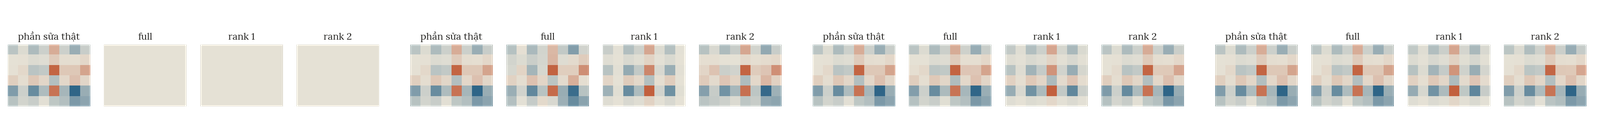

Dòng cuối giải thích độ cao của sàn. Phần sửa thật có hai giá trị kỳ dị khác 0 là 0.1668 và 0.108 (SVD, bài 2.9). Rank 1 giữ được tốt nhất hướng thứ nhất; hướng thứ hai bị bỏ. Vì các chiều input độc lập, phương sai 1, phần bị bỏ góp $0.108^2$ vào tổng bình phương sai số của mỗi mẫu, tức MSE khoảng $0.108^2/6\approx0.0019$ sau khi lấy trung bình trên 6 output, gần đúng mức đo được. Sai số của adapter rank $r$ vì vậy do các giá trị kỳ dị từ thứ $r+1$ trở đi quyết định. Trên model thật, phổ của phần sửa cần thiết không biết trước, nên rank là hyperparameter chọn bằng validation, và thứ tự chất lượng có thể đổi khi đổi dữ liệu, lớp được chèn hoặc ngân sách tối ưu.



**Hỏi nhanh.** Code đặt $\alpha = 2r$, và recipe cũng vậy. Tăng rank từ 4 lên 16 thì hệ số scale $\alpha/r$ thay đổi thế nào?

- A. Tăng 4 lần, vì $\alpha$ tăng 4 lần
- B. Giảm 4 lần, vì chia cho $r$ lớn hơn
- C. Phụ thuộc vào $d_{in}$ và $d_{out}$ của lớp
- D. Giữ nguyên bằng 2 với mọi rank

<details><summary>Đáp án</summary>

D. Giữ nguyên bằng 2 với mọi rank

$\alpha/r = 2r/r = 2$. Hai phương án đầu chỉ nhìn một nửa phân số. Nếu giữ $\alpha$ cố định mà tăng $r$ thì scale mới giảm, và cùng learning rate sẽ cho phần sửa nhỏ hơn. Vì vậy khi so nhiều rank, cần biết cấu hình đang theo kiểu nào. Scale không dính gì tới shape của lớp.

</details>

**Hỏi nhanh.** Dựng lại thí nghiệm, cùng input, nhưng phần sửa có hai giá trị kỳ dị là 0.1668 và 0.01, các giá trị khác bằng 0. Train rank 1 đủ lâu thì validation MSE khoảng bao nhiêu?

- A. Vẫn cỡ 0.002, vì phần sửa vẫn có hạng 2
- B. Cỡ $2\cdot 10^{-4}$, vì sàn giảm tỉ lệ với $\sigma_2$
- C. Cỡ $2\cdot 10^{-5}$, vì sàn giảm theo $\sigma_2^2$
- D. Bằng 0, vì rank 1 đã giữ được hướng mạnh nhất

<details><summary>Đáp án</summary>

C. Cỡ $2\cdot 10^{-5}$, vì sàn giảm theo $\sigma_2^2$

Phần mà rank 1 không biểu diễn được là hướng thứ hai, góp khoảng $\sigma_2^2/6 = 0.01^2/6 \approx 1.7\cdot 10^{-5}$ vào MSE trung bình trên 6 output. Hạng vẫn là 2, nhưng sai số do độ lớn của hướng bị bỏ quyết định, chứ không do hạng. Sàn tỉ lệ với bình phương của $\sigma_2$, nên giảm khoảng 117 lần, chứ không phải 11 lần. Đây là trực giác vì sao rank nhỏ thường là đủ: khi phần sửa dồn năng lượng vào vài hướng, các hướng còn lại góp rất ít.

</details>

## Merge để kiểm tính tương đương

Khi adapter đã học, có thể gộp $W=W_0+sBA$ để suy luận qua một ma trận. Với lớp tuyến tính đơn giản của bài, không dropout và không quantization, hai cách phải cho kết quả khớp trong sai số số thực. Nếu dùng quantization hoặc biến thể adapter, phải kiểm lại điều kiện merge của thư viện.

In [ ]:
with torch.no_grad():
    merged_weight = rank2_net.base + rank2_net.scale * rank2_net.B @ rank2_net.A
    separate = rank2_net(X_valid)
    merged = X_valid @ merged_weight.T
print("merge khop:", torch.allclose(separate, merged, atol=1e-10))
print("rank delta:", int(torch.linalg.matrix_rank(merged_weight - W0)))
torch.set_default_dtype(torch.float32)  # khôi phục mặc định sau phép tính float64

merge khop: True
rank delta: 2


`rank delta: 2` xác nhận phần đã gộp vào ma trận có đúng hạng 2, như cấu trúc $BA$ cho phép. Lưu adapter riêng cần lưu cả cấu hình và model nguồn đúng revision. Chỉ tệp A/B không tái tạo model nếu thiếu $W_0$. Merge lại vào một model nguồn khác dù cùng shape có thể cho output sai mà không báo lỗi. Không ghi đè asset nguồn duy nhất khi thử merge. Giữ base riêng còn có lợi: một base đi được với nhiều adapter cho nhiều nhiệm vụ; mỗi adapter chỉ là vài ma trận nhỏ, và đổi adapter là đổi nhiệm vụ.



**Hỏi nhanh.** Đội có một base và hai adapter học riêng trên base ấy: X để phân loại chủ đề đề bài, Y để gắn nhãn độ khó. Cần phục vụ cả hai nhiệm vụ. Làm thế nào cho đúng?

- A. Giữ nguyên $W_0$, gắn X hoặc Y tùy nhiệm vụ
- B. Merge cả X và Y vào cùng $W_0$ rồi dùng chung
- C. Cộng $B_X + B_Y$ và $A_X + A_Y$ thành một adapter
- D. Chỉ giữ adapter có validation tốt hơn, dùng cho cả hai

<details><summary>Đáp án</summary>

A. Giữ nguyên $W_0$, gắn X hoặc Y tùy nhiệm vụ

Mỗi adapter là phần sửa cho riêng nhiệm vụ của nó, tính trên $W_0$. Merge cả hai vào một ma trận thì nhiệm vụ nào cũng nhận thêm phần sửa của nhiệm vụ kia. Cộng từng ma trận còn tệ hơn: $(B_X + B_Y)(A_X + A_Y)$ sinh thêm hai số hạng chéo $B_XA_Y + B_YA_X$ không thuộc nhiệm vụ nào. Adapter tốt cho nhiệm vụ này không có lý do gì để tốt cho nhiệm vụ kia, và hai nhiệm vụ còn cần head khác nhau. Nếu cần mỗi nhiệm vụ một tệp, hãy merge từng adapter vào một bản sao riêng của base.

</details>

## Chèn LoRA vào một model Transformer

Trong model thật, LoRA không thay cả model mà bọc một số lớp Linear được chọn theo tên. DistilBERT có 6 block Transformer; mỗi block có bốn Linear $768\to768$ trong attention là `q_lin`, `k_lin`, `v_lin`, `out_lin` (query, key, value, output; bài 3.9), cùng hai Linear của MLP. Bài báo LoRA chủ yếu chèn adapter vào query và value; recipe cũng làm vậy. Head phân loại `pre_classifier` và `classifier` không có trong checkpoint gốc, được khởi tạo mới, nên phải học cùng adapter.

Code dưới dựng DistilBERT từ cấu hình mặc định của `transformers` với trọng số ngẫu nhiên. Kiến trúc và tên module giống checkpoint thật, nên đếm tham số và kiểm việc chèn adapter được mà không cần tải gì. Lớp `LoRALinear` là `TinyLoRA` viết lại để bọc một `nn.Linear` có sẵn, giữ cả bias gốc. Ta đóng băng mọi tham số cũ, bọc mỗi `q_lin`, `v_lin` bằng LoRA rank 4 với $\alpha=8$, rồi mở lại head.

In [ ]:
from transformers import DistilBertConfig, DistilBertForSequenceClassification

class LoRALinear(nn.Module):
    def __init__(self, base, rank, alpha):
        super().__init__()
        self.base = base  # nn.Linear gốc, kể cả bias
        self.A = nn.Parameter(torch.randn(rank, base.in_features) * 0.01)
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T

torch.manual_seed(4)
model = DistilBertForSequenceClassification(DistilBertConfig(num_labels=2)).eval()
token_ids = torch.randint(0, model.config.vocab_size, (2, 16))
with torch.no_grad():
    logits_before = model(input_ids=token_ids).logits

model.requires_grad_(False)
targets = [name for name, module in model.named_modules()
           if name.endswith(("q_lin", "v_lin")) and isinstance(module, nn.Linear)]
for name in targets:
    parent_name, child_name = name.rsplit(".", 1)
    parent = model.get_submodule(parent_name)
    base = getattr(parent, child_name)
    setattr(parent, child_name, LoRALinear(base, rank=4, alpha=8))
model.pre_classifier.requires_grad_(True)
model.classifier.requires_grad_(True)

with torch.no_grad():
    logits_after = model(input_ids=token_ids).logits
adapter_count = sum(p.numel() for n, p in model.named_parameters() if n.endswith((".A", ".B")))
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print("module duoc chen:", len(targets))
print("adapter:", adapter_count, "head:", trainable - adapter_count)
print("trainable:", trainable, "/", total, "=", f"{trainable / total:.2%}")
print("logits giu nguyen:", torch.allclose(logits_before, logits_after))

module duoc chen: 12
adapter: 73728 head: 592130
trainable: 665858 / 67028738 = 0.99%
logits giu nguyen: True


12 module đúng bằng 6 block nhân 2 lớp, và 73 728 tham số adapter khớp phép tính tay $12\cdot4\cdot(768+768)$. Head gồm `pre_classifier` ($768\times768$ cộng bias) và `classifier` ($768\times2$ cộng bias), tổng 592 130 tham số, gấp tám lần adapter. Phần được học thật vì vậy là 665 858 trên khoảng 67 triệu, chừng 1%; nếu chỉ đếm A, B thì con số là 0.11%. Logits giữ nguyên vì mọi $B$ bằng 0 và model ở chế độ `eval` (dropout tắt), nên đây là phép kiểm rằng việc bọc không làm hỏng forward.



**Hỏi nhanh.** Một báo cáo ghi: “LoRA rank 4 trên DistilBERT chỉ học 0.11% tham số.” Với cấu hình như code trên, head phân loại mới cũng được học. Nhận định nào đúng?

- A. Đúng, vì head đã có sẵn trong checkpoint pretrained
- B. Đúng, vì head chỉ có 1538 tham số của `classifier`
- C. Thiếu head, thật ra khoảng 0.99%, vì head gấp 8 lần adapter
- D. Sai, phải tính cả 67 triệu vì đều nằm trên đường backward

<details><summary>Đáp án</summary>

C. Thiếu head, thật ra khoảng 0.99%, vì head gấp 8 lần adapter

0.11% là $73\,728/67\,028\,738$, chỉ đếm A và B. Checkpoint DistilBERT gốc không có head cho nhiệm vụ mới, nên `pre_classifier` và `classifier` được khởi tạo và học, thêm 592 130 tham số. `classifier` chỉ là lớp cuối, còn `pre_classifier` cỡ $768\times 768$ mới là phần lớn. Tham số đóng băng có thể nằm trên đường backward, nhưng không có gradient được lưu lại và không có trạng thái optimizer.

</details>

[Recipe riêng](recipes/README.md) làm đúng các bước trên với checkpoint DistilBERT thật, dùng thư viện PEFT thay cho lớp tự viết. Script `text_experiment.py` kiểm hash từng tệp asset, ghi model ID và revision vào kết quả, kiểm rằng tên `q_lin`, `v_lin` tồn tại trước khi chèn, đặt `lora_alpha` bằng $2r$ và `lora_dropout` bằng 0.05, lưu head mới qua `modules_to_save`. Cùng script chạy bốn mode trên cùng tệp CSV train/validation, mỗi mode một tiến trình: `features` (trích embedding rồi học logistic regression), `head` (chỉ học head), `full` và `lora`. Mỗi lần chạy ghi `RESULT.json` với số tham số học, macro-F1 validation, thời gian chạy và, khi chạy trên CUDA, peak bộ nhớ của allocator. Máy thiếu PEFT thì mode `lora` dừng trước khi nạp asset. Kết quả đọc bằng cách đặt bốn dòng cạnh nhau: LoRA đáng giữ khi vượt head-only rõ rệt và gần full về macro-F1, trong khi thời gian và bộ nhớ thấp hơn.

Một so sánh dùng được cần ghi rõ batch size, độ dài token, precision, optimizer, số bước và thiết bị. Đếm riêng số tham số học không thay được đo peak memory. Với CUDA, đo thời gian phải đồng bộ trước/sau vùng tính; nếu không, đồng hồ CPU có thể chỉ đo thời gian xếp việc vào hàng đợi.

**Hỏi nhanh.** LoRA làm số tham số học của một lớp chỉ còn $1/256$. Đỉnh bộ nhớ GPU khi train có giảm còn $1/256$ không?

- A. Có, vì bộ nhớ khi train chủ yếu là gradient
- B. Không, vì vẫn còn trọng số gốc và activation
- C. Không, vì LoRA luôn tốn bộ nhớ hơn học toàn bộ
- D. Có, miễn là rank là một lũy thừa của 2

<details><summary>Đáp án</summary>

B. Không, vì vẫn còn trọng số gốc và activation

Chỉ gradient và trạng thái optimizer tỉ lệ với số tham số học. $W_0$ vẫn nằm trong bộ nhớ để forward, activation vẫn phải giữ để backward đi qua các lớp tới adapter, cộng thêm vùng làm việc của thư viện; mức giảm thật phải đo mới biết. LoRA thường tốn ít bộ nhớ hơn học toàn bộ, vì bỏ được gradient và trạng thái Adam của $W_0$, chỉ là không giảm đúng theo tỉ lệ tham số. Rank có là lũy thừa của 2 hay không thì chẳng liên quan.

</details>

## Bẫy cài đặt

Không bọc nhánh LoRA trong `no_grad()` chỉ vì trọng số nguồn đã đóng băng: A/B cần gradient. Khi adapter nằm trước một lớp gốc cố định, gradient vẫn có thể cần đi qua lớp cố định để về adapter; freeze trọng số không có nghĩa được cắt mọi đồ thị quanh lớp đó. Chọn sai tên module có thể chèn vào rất ít lớp hoặc không lớp nào, trong khi vòng lặp vẫn chạy êm. Kiểm danh sách tên, số module và số tham số trước khi train.

Nếu áp LoRA cả vào một lớp mà rank quá lớn, $r(d_{in}+d_{out})$ có thể lớn hơn $d_{in}d_{out}$. Công thức không hứa tiết kiệm với mọi $r$. Bias, head và các phần `modules_to_save` cũng phải cộng vào số trainable. Đừng chọn rank bằng test score; nó là hyperparameter cần validation.

**Hỏi nhanh.** Một script tự viết chèn LoRA vào những lớp có tên kết thúc bằng `query` và `value`, tức tên trong BERT. Chạy trên DistilBERT như mục trước, số tham số trainable in ra là 592 130. Chuyện gì đã xảy ra?

- A. Không lớp nào khớp tên, nên chỉ head được học
- B. Adapter chèn đủ, nhưng $B = 0$ nên không tính là trainable
- C. Rank quá nhỏ nên adapter bị làm tròn về 0
- D. Head bị freeze nhầm, còn adapter đã chèn đủ

<details><summary>Đáp án</summary>

A. Không lớp nào khớp tên, nên chỉ head được học

592 130 đúng bằng số tham số của `pre_classifier` cộng `classifier`. DistilBERT đặt tên `q_lin` và `v_lin`, nên bộ lọc `query`, `value` không khớp lớp nào, và vòng chèn chạy 0 lần mà không báo lỗi. `requires_grad` không phụ thuộc giá trị: $B$ bằng 0 vẫn là tham số được đếm. Nếu head bị freeze thì con số phải là 73 728. Vì vậy cần in ra số module đã chèn và so số trainable với số tính tay trước khi train. Recipe dừng hẳn khi không tìm thấy đúng các tên này.

</details>

## Khi đi thi

- **Kiểm một batch trước khi chạy dài.** In số module được chèn và số trainable, so với tính tay; xác nhận logits lúc khởi tạo trùng model gốc, gradient của A, B và head khác 0, còn trọng số gốc không có gradient.
- **Giữ baseline head-only.** Chạy cùng split, cùng độ dài token và cùng số bước; LoRA chỉ đáng giữ khi vượt head-only trên đúng metric của đề, và nên so với full nếu ngân sách cho phép.
- **Chọn rank bằng validation, bắt đầu nhỏ.** Rank nhỏ như recipe ($r=4$, $\alpha=2r$) chạy nhanh và cho một mốc; chỉ tăng rank khi validation còn kém full rõ rệt, không dò theo bảng điểm công khai.
- **Đo tài nguyên trên đúng máy.** Số tham số học không phải VRAM: đo peak memory và thời gian vài step với batch và độ dài thật trước khi chốt cấu hình.
- **Lưu đủ để tái tạo file nộp.** Adapter, head, cấu hình, model ID và revision của base; tải lại ở phiên mới, so logits rồi mới dự đoán test. Cần một tệp duy nhất thì merge vào bản sao, giữ base gốc.
- **Đọc luật về thư viện và asset.** Checkpoint pretrained, PEFT và GPU có được dùng hay không do thông báo của cuộc thi quy định; không có PEFT thì lớp bọc tự viết như trong bài đủ cho các lớp Linear.

## Tóm tắt

LoRA học $\Delta W=sBA$ trong khi giữ $W_0$ cố định. Shape quyết định số tham số $r(d_{in}+d_{out})$ và hạng tối đa $r$; khi rank quá nhỏ, sai số do các giá trị kỳ dị bị bỏ của phần sửa quyết định. A ngẫu nhiên, B bằng 0 giữ output nguồn nhưng vẫn có đường học ở bước đầu. Kiểm gradient và merge bắt lỗi cài đặt. Trong model thật, adapter được chèn theo tên module, và head mới có thể chiếm phần lớn số tham số học. Tiết kiệm tham số không tự chứng minh chất lượng hay bộ nhớ; so thực nghiệm cần cùng split, ngân sách, metric và số đo tài nguyên.

## Kiểm tra cuối bài

**Câu 1.** LoRA cơ bản: $W_0$ đã freeze, còn $A$ và $B$ trainable và nằm trong optimizer. Sau 100 bước train, so với lúc khởi tạo, tham số nào đã đổi giá trị?

- A. Không tham số nào, vì cả lớp đã bị freeze
- B. Chỉ $B$, vì gradient của $A$ luôn bằng 0
- C. $A$ và $B$, còn $W_0$ giữ nguyên
- D. Cả $W_0$, $A$ lẫn $B$, vì đều tham gia forward

<details><summary>Đáp án</summary>

C. $A$ và $B$, còn $W_0$ giữ nguyên

Freeze chỉ tắt gradient của $W_0$, còn $A$ và $B$ vẫn học. Gradient của $A$ chỉ bằng 0 ở bước đầu, khi $B$ còn bằng 0; từ bước sau, $A$ nhận gradient. Tham gia forward không có nghĩa là được cập nhật: tham số phải có `requires_grad` và phải nằm trong optimizer.

</details>

**Câu 2.** Một lớp Linear $50 \to 100$, tức $W_0$ có shape $100\times 50$. Một bạn đặt LoRA $r = 64$ “cho chắc”. Nhận định nào đúng?

- A. $\Delta W$ có hạng tối đa 50, và adapter có 9600 tham số, nhiều hơn 5000 của học toàn bộ
- B. $\Delta W$ có hạng tối đa 64, và adapter có 9600 tham số, nhiều hơn 5000 của học toàn bộ
- C. $\Delta W$ có hạng tối đa 50, và adapter vẫn ít tham số hơn học toàn bộ
- D. $\Delta W$ có hạng tối đa 64, và adapter vẫn ít tham số hơn học toàn bộ

<details><summary>Đáp án</summary>

A. $\Delta W$ có hạng tối đa 50, và adapter có 9600 tham số, nhiều hơn 5000 của học toàn bộ

Ma trận $100\times 50$ có hạng không quá $\min(100, 50) = 50$, nên 14 hướng thêm của $r = 64$ không biểu diễn được gì mới. Adapter có $64\cdot(50 + 100) = 9600$ tham số, gần gấp đôi $100\cdot 50 = 5000$ của học toàn bộ. LoRA chỉ tiết kiệm khi $r(d_{in} + d_{out}) < d_{in}d_{out}$, ở lớp này là khi $r \le 33$.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 30](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=14)

</details>

**Câu 3.** Đội cần thích nghi một model ngôn ngữ lớn cho bài thi, chỉ với một GPU. Một bạn đề xuất LoRA, và lập luận thêm: “Model nộp sẽ dự đoán nhanh hơn, vì chỉ có vài trăm nghìn tham số.” Nhận định nào đúng?

- A. Đúng, vì lúc dự đoán chỉ cần A và B nên nhanh hơn base nhiều
- B. LoRA làm fine-tune rẻ hơn, nhưng lúc dự đoán input vẫn đi qua toàn bộ base
- C. LoRA cho phép dùng base lớn hơn mà không tốn thêm bộ nhớ khi suy luận
- D. LoRA tạo thêm dữ liệu train nên bớt công gán nhãn

<details><summary>Đáp án</summary>

B. LoRA làm fine-tune rẻ hơn, nhưng lúc dự đoán input vẫn đi qua toàn bộ base

LoRA giảm số tham số cần gradient và trạng thái optimizer, nên fine-tune vừa GPU hơn và adapter lưu gọn. Lúc dự đoán, input vẫn đi qua toàn bộ $W_0$. Để nhánh adapter riêng thì tốn thêm một chút phép tính, còn merge xong thì chi phí bằng đúng base. Kích thước của base quyết định bộ nhớ khi suy luận, và LoRA không sinh ra dữ liệu.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 246](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=88)

</details>

**Câu 4.** Một biến thể khởi tạo ngược lại: $A = 0$, $B$ ngẫu nhiên. Ở bước đầu, điều gì đúng?

- A. Output đổi ngay, gradient của $A$ bằng 0
- B. Output đổi ngay, gradient của $B$ bằng 0
- C. Output giữ nguyên, gradient của $A$ bằng 0
- D. Output giữ nguyên, gradient của $B$ bằng 0

<details><summary>Đáp án</summary>

D. Output giữ nguyên, gradient của $B$ bằng 0

$BA = 0$ vì $A = 0$, nên output vẫn là $W_0\mathbf{x}$. $\partial L/\partial B = sG^\top XA^\top$ chứa $A = 0$ nên bằng 0, còn $\partial L/\partial A = sB^\top G^\top X$ khác 0 vì $B$ ngẫu nhiên. Vai trò hai ma trận đổi chỗ cho nhau, và nhánh vẫn học được. Điều cần chỉ là một ma trận bằng 0 để giữ nguyên output gốc, ma trận kia khác 0 để gradient có đường đi.

</details>

**Câu 5.** Sau khi train, $\Delta W = \frac{\alpha}{r}BA$ của một lớp $4096\times 4096$ với $r = 8$. Nhận định nào đúng về $\Delta W$ và $W = W_0 + \Delta W$?

- A. $\Delta W$ khả nghịch khi $A$, $B$ tổng quát, và $W$ cũng khả nghịch
- B. $\Delta W$ khả nghịch khi $A$, $B$ tổng quát, còn $W$ có thể suy biến
- C. $\Delta W$ luôn suy biến, còn $W$ vẫn có thể khả nghịch
- D. $\Delta W$ luôn suy biến, vì vậy $W$ cũng suy biến

<details><summary>Đáp án</summary>

C. $\Delta W$ luôn suy biến, còn $W$ vẫn có thể khả nghịch

Hạng của $BA$ không vượt quá $r = 8 < 4096$, nên phương trình $\Delta W\mathbf{x} = \mathbf{0}$ có không gian nghiệm ít nhất $4096 - 8 = 4088$ chiều. Như vậy $\Delta W$ có trị riêng 0, và ma trận có trị riêng 0 thì suy biến, dù $A$, $B$ được khởi tạo thế nào. Cộng thêm $W_0$ thì khác. Chẳng hạn với $W_0 = I$, trị riêng của $I + \Delta W$ là $1 + \lambda$ với $\lambda$ là trị riêng của $\Delta W$, phần lớn bằng 1, nên tổng thường vẫn khả nghịch. Phần sửa suy biến không có nghĩa là tổng cũng suy biến.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 26](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=13)

</details>

**Câu 6.** Vì sao một adapter hạng thấp thường đủ để thích nghi model pretrained cho một nhiệm vụ mới?

- A. Ta giả định phần sửa cho nhiệm vụ mới chỉ cần ít hướng
- B. Mọi ma trận trọng số pretrained vốn đã có hạng thấp
- C. Tích $BA$ gom các output thành vài nhóm xử lý như nhau
- D. Tích $BA$ tính tương quan giữa các trọng số nhanh hơn

<details><summary>Đáp án</summary>

A. Ta giả định phần sửa cho nhiệm vụ mới chỉ cần ít hướng

LoRA đặt cược rằng $\Delta W$ cần cho nhiệm vụ mới dồn năng lượng vào ít hướng, giống ý tưởng phân tích ma trận trong hệ gợi ý: quan hệ giữa người dùng và sản phẩm được mô tả trong một không gian ít chiều. Đó là một giả định, được kiểm bằng validation khi đổi rank. $W_0$ thường có hạng đầy đủ, và LoRA không đòi $W_0$ phải hạng thấp. $BA$ không gom output thành cụm: mỗi output nhận một tổ hợp riêng của $r$ hướng. Rank thấp là để tiết kiệm tham số, không phải để tính tương quan.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q7.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=38)

</details>

**Câu 7.** $W_0$ có shape $(6, 8)$, $A$ có shape $(2, 8)$, $B$ có shape $(6, 2)$, $\alpha = 4$, $r = 2$. Ma trận merge dùng để suy luận, không có dropout, là gì?

- A. $W_0 + 0.5\,BA$
- B. $W_0 + 2\,BA$
- C. $W_0 + 2\,AB$
- D. $W_0 + BA$

<details><summary>Đáp án</summary>

B. $W_0 + 2\,BA$

Scale là $\alpha/r = 4/2 = 2$. $BA$ có shape $(6, 8)$, khớp với $W_0$. $AB$ có shape $(2, 2)$, không cộng được. Quên scale hoặc lấy nhầm $r/\alpha$ thì output sau khi merge lệch với output khi chạy nhánh riêng, và phép kiểm `allclose` như trong bài sẽ bắt được ngay.

</details>

**Câu 8.** Có tệp adapter đã train, nhưng chưa có base model. Muốn tái tạo đúng dự đoán, cần thêm gì?

- A. Đổi tên adapter thành `model.safetensors` để nạp như một model độc lập
- B. Một base bất kỳ có cùng kiến trúc và cùng số tham số
- C. Chỉ cần tokenizer có cùng kích thước vocabulary
- D. Đúng base và revision đã dùng khi train, cùng cấu hình và tokenizer

<details><summary>Đáp án</summary>

D. Đúng base và revision đã dùng khi train, cùng cấu hình và tokenizer

Adapter chỉ chứa phần sửa $A$, $B$, cộng head nếu được lưu kèm, và phần sửa ấy tính trên đúng $W_0$ kia. Một base khác revision có thể cùng shape nhưng khác trọng số: merge vẫn chạy, không báo lỗi, chỉ có output là sai. Tokenizer cùng kích thước vẫn có thể đổi token theo cách khác. Đổi tên tệp không tạo ra được $W_0$.

</details>

**Câu 9.** Đội đã full fine-tune một lớp $768\times 768$, và có $\Delta W = W_{ft} - W_0$. Muốn thay bằng một adapter rank 8 để lưu gọn, sao cho $\lVert\Delta W - BA\rVert_F$ nhỏ nhất. Làm thế nào?

- A. Giữ 8 hàng có độ dài lớn nhất của $\Delta W$, các hàng khác bằng 0
- B. Lấy 8 cột đầu của $\Delta W$ làm $B$, và 8 hàng đầu làm $A$
- C. Phân tích SVD của $\Delta W$, rồi giữ 8 giá trị kỳ dị nhỏ nhất cùng vector của chúng
- D. Phân tích SVD của $\Delta W$, rồi giữ 8 giá trị kỳ dị lớn nhất cùng vector của chúng

<details><summary>Đáp án</summary>

D. Phân tích SVD của $\Delta W$, rồi giữ 8 giá trị kỳ dị lớn nhất cùng vector của chúng

Theo định lý Eckart–Young, xấp xỉ hạng $r$ tốt nhất theo chuẩn Frobenius là SVD cắt cụt (bài 2.9): $B = U_8\Sigma_8$, $A = V_8^\top$, và sai số bình phương bằng tổng bình phương các giá trị kỳ dị bị bỏ. Giữ 8 hàng cũng cho hạng không quá 8, nhưng xóa trắng mọi hàng khác. Tích của 8 cột đầu với 8 hàng đầu không liên quan gì tới $\Delta W$. Giữ các giá trị kỳ dị nhỏ nhất là bỏ đúng phần năng lượng lớn nhất. Adapter trích ra như vậy tốt đến đâu thì còn tùy phổ của $\Delta W$, giống sàn MSE của rank 1 trong bài.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.14](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=14)

</details>

**Câu 10.** $W_0$ đã freeze. Code train adapter đặt cả phép tính `W0 x + scale * B(A x)` trong `torch.no_grad()`. Sửa thế nào để giữ được gradient cho việc học $A$, $B$?

- A. Giữ `no_grad`, thêm $A$, $B$ vào optimizer thêm lần nữa
- B. Bỏ `no_grad` khỏi nhánh adapter, vẫn giữ $W_0$ đóng băng
- C. Giữ `no_grad`, gọi `requires_grad_()` cho output sau khối
- D. Giữ `no_grad`, tăng scale cho gradient đủ lớn

<details><summary>Đáp án</summary>

B. Bỏ `no_grad` khỏi nhánh adapter, vẫn giữ $W_0$ đóng băng

`no_grad` khiến autograd không ghi lại phép tính của nhánh adapter, nên `backward` không có đường đi về $A$, $B$. Bật `requires_grad` cho output sau khối chỉ tạo ra một tensor lá mới, không phục hồi được đồ thị đã bị bỏ. Optimizer và scale đều không tạo ra gradient. Freeze $W_0$ chỉ cần đặt `requires_grad=False` cho $W_0$, không đòi phải tắt đồ thị của $A$, $B$.

</details>

## Đọc thêm

- Hu và cộng sự — [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685): đọc công thức nhánh sửa và giới hạn của các kết quả thực nghiệm trong paper.
- [PEFT — LoRA guide](https://huggingface.co/docs/peft/developer_guides/lora): kiểm khởi tạo A/B, scale, target modules và các biến thể.
- [PEFT — adapter checkpoint format](https://huggingface.co/docs/peft/developer_guides/checkpoint): hiểu vì sao adapter cần model nguồn cùng cấu hình.
- [PyTorch — autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html): hiểu gradient vẫn cần đi qua trọng số bị freeze trong một số đồ thị.